# Combining vector and gridded data

In the first half of the course, we learned the foundations of using Python to interacting with geospatial data. Today, we will think about how we can combine different data types to extract more useful quantiative information.

Specifically, we will be looking at how we can use a combination of GeoPandas and (rio)xarray to allow interactions between vector and raster data, allowing us to perform more precise quantiative analysis of specific spatial targets.

This session will also give you a small working example of how you might interrogate satellite data through time, which might be useful as you continue to consider your final projects.

In [2]:
import geopandas as gpd 
import pandas as pd
import rioxarray as rxr
import xarray as xr

import matplotlib.pyplot as plt

from shapely.geometry import box
from pathlib import Path

## Data

In this session, we will be using the case study of fires that took place in the UK in 2026: given the extreme heatwaves that took place over the summer, these were [particularly extensive](https://www.theguardian.com/world/2026/oct/08/july-record-wildfires-england-data-shows). 

I identified a suitable wildfire using European Forest Fire Information System (EFFIS) data. EFFIS [publishes observations of European forest fire extents from MODIS and VIIRS data](https://forest-fire.emergency.copernicus.eu/applications/data-and-services) on their website. The full shapefile is large (>200 mb) but you can [view a sample of the 2026 data on Wikimedia](https://commons.wikimedia.org/wiki/Data:2026_European_wildfires.map)). From this dataset I have extracted a single polygon representing the extent of [a particularly large forest fire near Powys, Wales](https://www.theguardian.com/uk-news/2026/apr/30/powys-wildfires-fifth-day-public-urged-to-stay-away), that took place on the 27th April, 2026. You can download it here:

 - [EFFIS MODIS-derived extent of Powys wildfire](https://raw.githubusercontent.com/trchudley/geospatial-scientific-computing/main/week/07/effis_modis_powys_20260427.gpkg)

Ensure it is saved as `effis_modis_powys_20260427.gpkg` within this directory.
  

In [3]:
fire_gdf = gpd.read_file("effis_modis_powys_20260427.gpkg")

fire_gdf

,id,FIREDATE,FINALDATE,LASTUPDATE,COUNTRY,PROVINCE,COMMUNE,AREA_HA,BROADLEA,CONIFER,MIXED,SCLEROPH,TRANSIT,OTHERNATLC,AGRIAREAS,ARTIFSURF,OTHERLC,PERCNA2K,CLASS,geometry
0,417503,2026-04-29 10:21:00,2026-05-01 01:58:00,2026-04-27 09:49:04.453044,UK,Powys,Powys,6367,0,0,0,0,0,99.99999999999842,0,0,0,99.53978713047633,FireSeason,"MULTIPOLYGON (((-3.74788 52.34869, -3.74809 52..."


In [4]:
fire_gdf.explore()

We also need satellite data to support our analysis of the fire. I am going to use the geopandas outline to extract a bounding box for Landsat data. Below, I convert the dataframe to the relevant UTM Zone (UTM 30N, same as Bristol - we're not that far away!) and buffer the data by 2km to give us some space at the edges of the image. I get the bounding box both in UTM 30N as well as latitude/longitude (i.e. EPSG:4326) to form the basis of a bounding box for searching the STAC.

In [5]:
fire_gdf = fire_gdf.to_crs(32630)

utm_30n_bounds = fire_gdf.buffer(2000).bounds.values[0]
lat_lon_bounds = fire_gdf.buffer(2000).to_crs("EPSG:4326").bounds.values[0]

print(utm_30n_bounds)
print(lat_lon_bounds)

[ 445356.31329643 5786900.56142021  460086.65866444 5803866.73352778]
[-3.80182451 52.23087296 -3.58495919 52.38308418]


I won't bore you with the download code - you've seen it before - but I've made the script available within [the recipes section](../../recipes/batch-download-landsat.ipynb). What could be useful for you is that I've slightly edited the script to allow us to download a full stack of imagery, rather than just selecting one. 

The four images can be downloaded here:

 - Download [Landsat 8/9 images of Powys wildfire](https://raw.githubusercontent.com/trchudley/geospatial-scientific-computing/main/week/07/powys_data.zip)

Download and unzip the images. The below code assumed you have a directory `powys_data` in the same directory as the Notebook which contains all the `.tif` files.


:::{note} Obtaining vector outlines for your own projects
If you are interested in performing a parrallel assessment of a specific region in your final project, you may be able to find a similar public dataset that will provide you with an AOI. However, you could also choose to create one yourself. I will [explain how you can do this in today's exercises](./exercises-week-07.ipynb#draw-a-new-region-of-interest-roi-polygon).
:::

## Examining vector and raster data together

Let's get all the files in the directory. We can once again make use of `pathlib` / `Path` to get our filepaths aligned. By using the handy `glob` function, we can search of all the files within the directory that contain a specific pattern - here `'*.tif'` (where `*` is a 'wildcard' operator).

In [6]:
directory = Path("powys_data")

# Get all the  *.tif files in the directory as a list
files = list(directory.glob('*.tif'))

# Ensure files are sorted alphpabetically
files = sorted(files)

# Visualise the files
files

[PosixPath('powys_data/powys_2026-04-22_LC92030242026112LGN00.tif'),
 PosixPath('powys_data/powys_2026-04-29_LC92040242026119LGN00.tif'),
 PosixPath('powys_data/powys_2026-04-30_LC82030242026120LGN00.tif'),
 PosixPath('powys_data/powys_2026-05-24_LC92030242026144LGN00.tif')]

Let's load the first and second image to compare. As we will be performing the same operation twice, we can create a small function to avoid us having to write the same code again!

In [12]:
def load_image_and_get_date(fpath):

    # Load the raster image using rioxarray
    scene = rxr.open_rasterio(fpath).squeeze()
    scene['band'] = list(scene.attrs["long_name"])

    # Get the date from the filename (assuming the date is in between the second and third underscores)
    date_str = fpath.stem.split('_')[1]

    return scene, date_str

before_ds, before_date = load_image_and_get_date(files[0])

after_ds, after_date = load_image_and_get_date(files[1])

Now we can plot the two images alongside eath other. However, as we have our vector data (and **we know that they are in the same projection** - this is a common mistake!), we can plot the vector outline on top, and see whether they match.

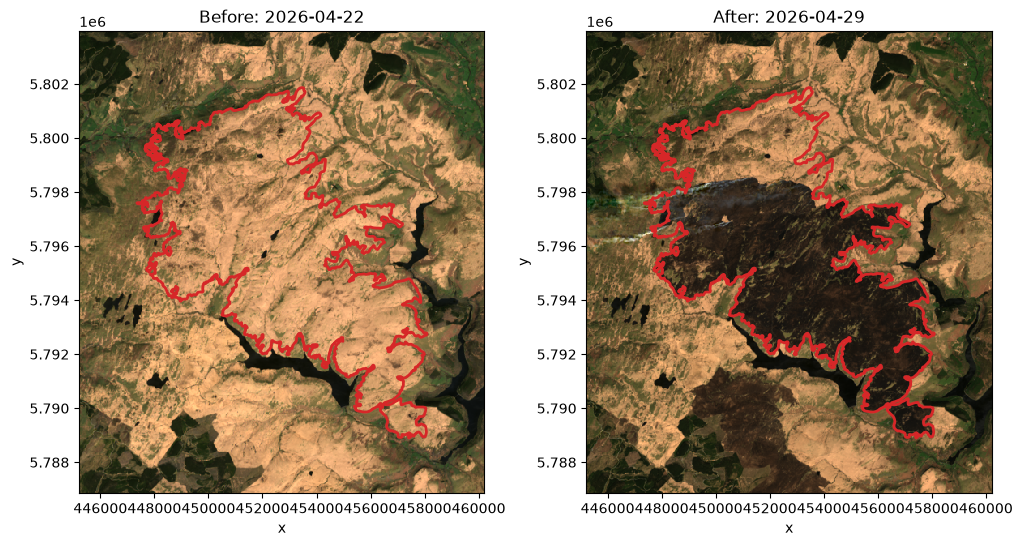

In [13]:
# Rather than using "robust=True" to let matplotlib automatically determine the min and max 
# values for the color scale, we can set them manually to ensure that both images are 
# displayed with the same color scale.
vmin, vmax = 0, 0.25

fig, axes = plt.subplots(ncols=2, figsize=(12, 6))

ax = axes[0]

before_ds.sel(band=["red", "green", "blue"]).plot.imshow(ax=ax, vmin=vmin, vmax=vmax)
fire_gdf.plot(ax=ax, facecolor="none", edgecolor="tab:red", linewidth=2) 
ax.set_title(f"Before: {before_date}")
ax.set_aspect('equal')

# Note: plots are drawn in the order they are called, so the fire outline will 
# need to be called after the image to appear on top.

ax = axes[1]

after_ds.sel(band=["red", "green", "blue"]).plot.imshow(ax=ax, vmin=vmin, vmax=vmax)
fire_gdf.plot(ax=ax, facecolor="none", edgecolor="tab:red", linewidth=2)
ax.set_title(f"After: {after_date}")
ax.set_aspect('equal')

plt.show()

It definitely looks like we can see the fire scar, and that the EFFIS data has accurately captured the extent of the southern half! (the rest of the extent burns in the following days, as we will see in the section 3).

Let's explore the use of the Normalised Burn Ratio (NBR), which we calcualte from the `nir` and `swir22` bands.

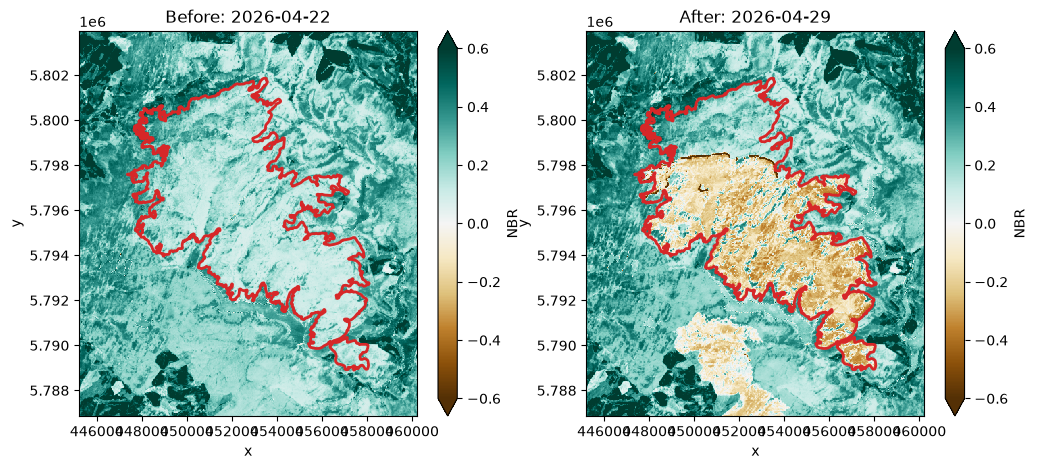

In [14]:
# Calculate the Normalized Burn Index (NBI)
nbr_before = (before_ds.sel(band="nir08") - before_ds.sel(band="swir22")) / (before_ds.sel(band="nir08") + before_ds.sel(band="swir22"))
nbr_after = (after_ds.sel(band="nir08") - after_ds.sel(band="swir22")) / (after_ds.sel(band="nir08") + after_ds.sel(band="swir22"))

# Adjust 'long_name' attribute to reflect the new variable
nbr_before.attrs['long_name'] = "Normalized Burn Index"
nbr_after.attrs['long_name'] = "Normalized Burn Index"

# Set the color scale limits for the NBI plots.
vmin, vmax = -.6, .6

# Begin plotting
fig, axes = plt.subplots(ncols=2, figsize=(12, 5))

ax = axes[0]
nbr_before.plot.imshow(ax=ax, vmin=vmin, vmax=vmax, cmap="BrBG", cbar_kwargs={"label": "NBR"})
fire_gdf.plot(ax=ax, facecolor="none", edgecolor="tab:red", linewidth=2) 
ax.set_title(f"Before: {before_date}")
ax.set_aspect('equal')

# Note: plots are drawn in the order they are called, so the fire outline will 
# need to be called after the image to appear on top.

ax = axes[1]

nbr_after.plot.imshow(ax=ax, vmin=vmin, vmax=vmax, cmap="BrBG", cbar_kwargs={"label": "NBR"})
fire_gdf.plot(ax=ax, facecolor="none", edgecolor="tab:red", linewidth=2)
ax.set_title(f"After: {after_date}")
ax.set_aspect('equal')

plt.show()

Note that positive values indicate healthy vegetation, whilst negative values indicate recently burned areas.

## Using `geopandas` objects to clip `rioxarray` objects

A particularly useful interaction between `vector` and `raster` data is that rasters can be clipped to vector extents using [the `rasterio` `clip` function](https://vylor.github.io/rioxarray/stable/rioxarray.html#rioxarray.raster_array.RasterArray.clip). This works in much the same you as you'd expect to see from a vector-only clip operation:

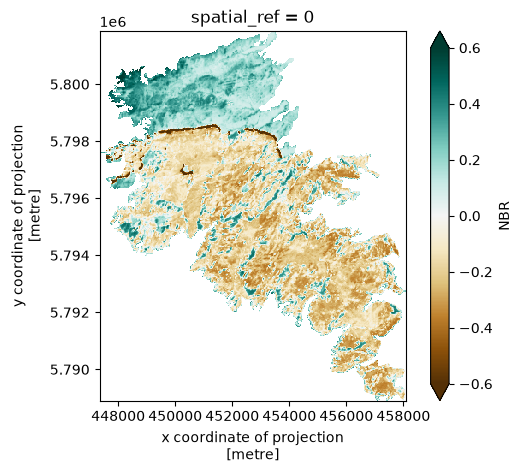

In [15]:
nbr_after_clipped = nbr_after.rio.clip(fire_gdf.geometry)

vmin, vmax = -.6, .6

fig, ax = plt.subplots()
nbr_after_clipped.plot.imshow(vmin=vmin, vmax=vmax, cmap="BrBG", cbar_kwargs={"label": "NBR"})
ax.set_aspect('equal')

It is worth knowing a few of the optional arguments for `clip`, because they can result in a quite different results:

 - **`all_touched`** (`bool`, optional, defaults to `False`) – If `True`, all pixels *touched* by geometries will be retained. If false, only pixels whose *center is within the polygon* will be retained.
 - **`drop`** (`bool`, optional, defaults to `True`) – If `True`, drop the data outside of the extent of the mask geometries Otherwise, it will return the same raster with the data masked. 
 - **`invert`** (`bool`, optional, defaults to `False`) – If `False`, pixels that do not overlap shapes will be set as nodata. Otherwise, pixels that overlap the shapes will be set as nodata. 

Try adding these options to the above cell and see what changes (you might not be able to see anything for `all_touched` at this scale).

Knowing which output you are getting important if you would like to carry on comparing datasets, because different settings for `all_touched` and `drop` can result in datasets of different sizes:

In [16]:
original_shape = nbr_after.shape
clipped_shape = nbr_after_clipped.shape

print(f"Original shape: {original_shape}, Clipped shape: {clipped_shape}")

Original shape: (570, 500), Clipped shape: (432, 358)


Performing operations on datasets of different sizes (i.e. band maths) will raise an error, or may even 'silently fail' by returning invalid values.

## Vectorisation and Rasterisation

It is possible to convert vector data to raster data, and vice versa.

### Vectorisation

Vectorisation will convert a rioxarray dataframe into a geopandas dataframe. Let's try and threshold our NDI image to get a roughly matching dataframe:

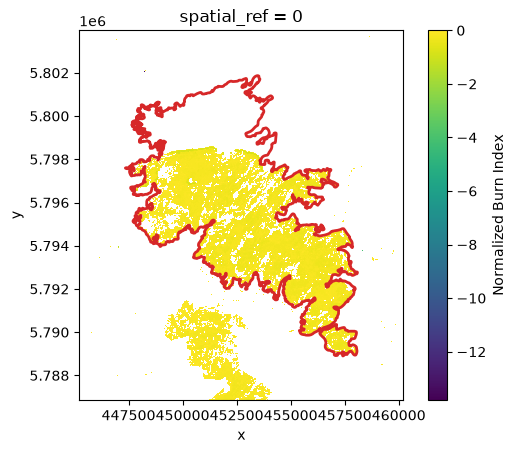

In [22]:
nbr_threshold = 0.0

nbr_after_thresholded = nbr_after.where(nbr_after <= nbi_threshold)

fig, ax = plt.subplots()
nbr_after_thresholded.plot.imshow(ax=ax)
fire_gdf.plot(ax=ax, facecolor="none", edgecolor="tab:red", linewidth=2)

plt.show()

The code to produce a geodataframe is simple but isn't sadly isn't wrapped in a nice function - instead, we need to import a function from the underlying `rasterio` package:

In [23]:
from rasterio.features import shapes
from shapely.geometry import shape

# Extract shapes and values
shape_gen = (
    {"properties": {"value": v}, "geometry": shape(s)}
    for s, v in shapes(nbr_after_thresholded.values, transform=nbr_after_thresholded.rio.transform())
)

# Convert to GeoDataFrame
nbr_after_thresholded_gdf = gpd.GeoDataFrame.from_features(list(shape_gen), crs=nbr_after_thresholded.rio.crs)


That took a few second to produce, which is strange. Let's see what we've got:

<Axes: >

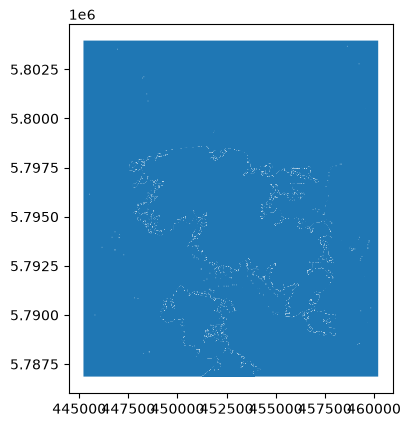

In [24]:
nbr_after_thresholded_gdf.plot()

Oh no - this isn't quite we expected! Let's examine the dataframe:

In [26]:
nbr_after_thresholded_gdf

,geometry,value
0,"POLYGON ((458625 5803695, 458625 5803665, 4586...",-0.015774
1,"POLYGON ((446925 5803545, 446925 5803515, 4469...",-0.018471
2,"POLYGON ((459225 5802795, 459225 5802765, 4592...",-0.024129
3,"POLYGON ((448275 5802135, 448275 5802105, 4483...",-0.246358
4,"POLYGON ((448215 5802075, 448215 5802045, 4482...",-13.802158
...,...,...
52800,"POLYGON ((453825 5786895, 453825 5786865, 4538...",-0.094840
52801,"POLYGON ((453855 5786895, 453855 5786865, 4538...",NaN
52802,"POLYGON ((453885 5786895, 453885 5786865, 4539...",-0.048847
52803,"POLYGON ((453915 5786895, 453915 5786865, 4539...",-0.084224


OK, it's clearer what's gone on. The vectorise process doesn't simply produce nice polygon of all the non-nan regions we've included. Instead, it produces an _individual polygon_ for each _contiguous region of pixels with the same value_. This is great for thematic data (i.e. 1 = road, 2 = forest, 3 = building) as it will convert things nicely. However, our data, which we produced from the `xarray` `where` function, is `float` data - nearly every pixel has different value to the ones around it, so we end up with a massive geodataframe where nearly every pixel is it's own shape!

For these types of data, it's better to create a boolean dataset, so that the only values are `0` and `1`. Then, we can simply filter out the geopandas rows where the value is `0`.

In [27]:
# Get boolean mask of pixels below the threshold
nbr_after_thresholded_bool = nbr_after_thresholded <= nbr_threshold

# Must convert from bool (True, False) to int (1, 0) for shapes() to work correctly
nbr_after_thresholded_bool = nbr_after_thresholded_bool.astype(int)

# Extract shapes and values
shape_gen = (
    {"properties": {"value": v}, "geometry": shape(s)}
    for s, v in shapes(nbr_after_thresholded_bool.values, transform=nbr_after_thresholded_bool.rio.transform())
)

# Convert to GeoDataFrame
nbr_after_thresholded_bool_gdf = gpd.GeoDataFrame.from_features(list(shape_gen), crs=nbr_after_thresholded_bool.rio.crs)

# Remove polygons with value 0 (not below threshold)
nbr_after_thresholded_bool_gdf = nbr_after_thresholded_bool_gdf[nbr_after_thresholded_bool_gdf["value"] == 1]

This produces a much better mask:

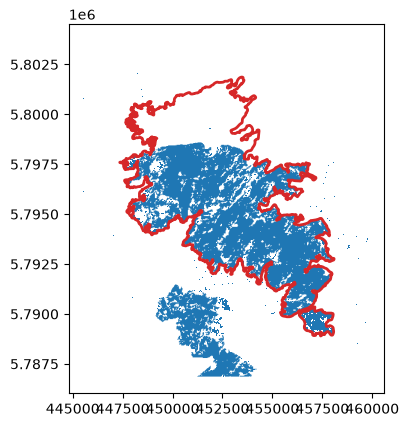

In [28]:
fig, ax = plt.subplots()
nbr_after_thresholded_bool_gdf.plot(ax=ax)
fire_gdf.plot(ax=ax, facecolor="none", edgecolor="tab:red", linewidth=2)
plt.show()

We can now do various geopandas things, if we so like. For instance, it's slightly easier to manipulate clipping and calculate area through geopandas:

In [29]:
# Calculate total burned area within image extent (not clipped to fire_gdf)
total_burned_area = nbr_after_thresholded_bool_gdf.area.sum() / 1e6  # Convert from m² to km²

print(f"Total classified burned area in image: {total_burned_area:.2f} km²")

# Calculate total burned area within fire_gdf extent by clipping the burned area polygons to the fire_gdf extent
nbr_after_thresholded_bool_gdf_clipped = gpd.clip(nbr_after_thresholded_bool_gdf, fire_gdf)
total_burned_area_clipped = nbr_after_thresholded_bool_gdf_clipped.area.sum() / 1e6  # Convert from m² to km²

print(f"Total classified burned area within EFFIS fire extent: {total_burned_area_clipped:.2f} km²")

# Calculate the total area of the fire_gdf polygon
total_fire_area = fire_gdf.area.sum() / 1e6  # Convert from m² to km²
print(f"Total EFFIS fire area: {total_fire_area:.2f} km²")

Total classified burned area in image: 46.82 km²
Total classified burned area within EFFIS fire extent: 38.50 km²
Total EFFIS fire area: 63.62 km²


### Rasterisation

It is possible to do the reverse: convert a `geopandas` dataframe into an `xarray` raster.

There is an simple way and a more complex way to do this. If you are just interested in getting a boolean mask of where you vector data exists, you could simply create an `xarray` dataset where all values are equal to zero, and then clip the data. This will produce an `xarray` `dataarray` where all vector-bounded values are equal to `1`:

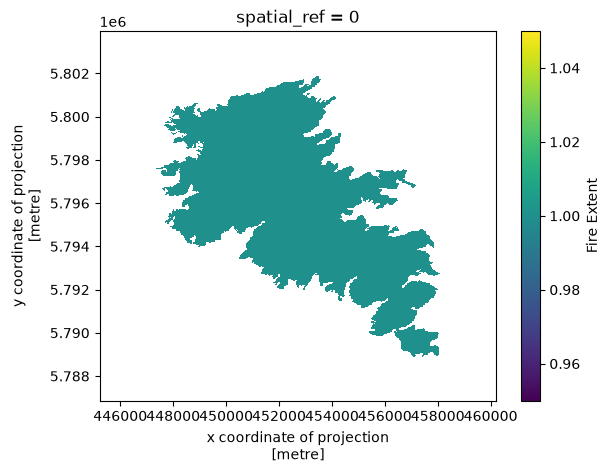

In [30]:
fire_xds = (nbr_after * 0) + 1  # multiply by 0 to get an array of zeros, then add 1 to get an array of ones
fire_xds.attrs['long_name'] = "Fire Extent"

fire_gdf_xds = fire_xds.rio.clip(fire_gdf.geometry, drop=False)

fire_gdf_xds.plot.imshow()

However, there are certain situations where you might want to construct an `xarray` dataset where the array values are equal to some column in the geodataframe. For instance, imagine you had a geodataframe that has a thematic `['class']` column (1 = road, 2 = forest, 3 = building). You might want to produce a matching raster where the values match the class. 

Here, we can rely on additional small package [called `geocube`, which helps the conversion between `geopandas` and `rioxarray` data](https://vylor.github.io/geocube/stable/examples/categorical.html). I won't ask you to install this in this class: just know that it is useful for you if you need it. You can access it the usual way (`conda install -c conda-forge geocube)`).

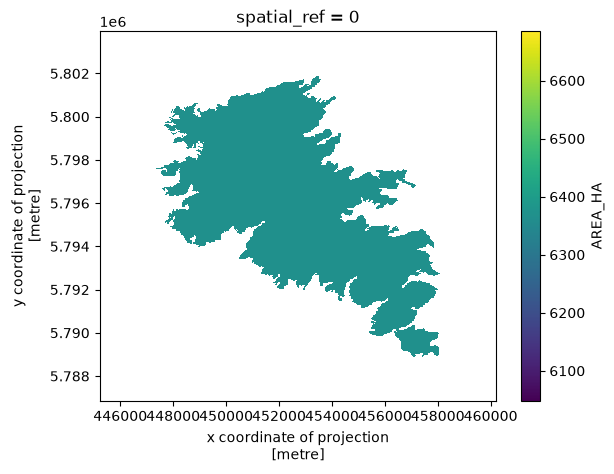

In [31]:
from geocube.api.core import make_geocube

# Ensure that the AREA_HA column is numeric and not interpreted as a string. If there are any non-numeric values, they will be converted to NaN.
fire_gdf["AREA_HA"] = pd.to_numeric(fire_gdf["AREA_HA"], errors='coerce')

# Use the `make_geocube` function to rasterize the fire_gdf with the AREA_HA attribute
fire_gdf_xds_class = make_geocube(
    vector_data=fire_gdf, 
    measurements=["AREA_HA"],
    like=nbr_after,
    )

# Plot the rasterized AREA_HA values
fire_gdf_xds_class["AREA_HA"].plot.imshow()

Note that the value of the pixels are now `6367`. If our geodataframe had multiple polygons with different `AREA_HA` values, the pixel values within those regions would match accordingly.

## Summary

We have seen how we can begin to use vector and raster in combination within the Python geospatial stack: plotting raster and vector together, using vector data to clip raster datasets, and converting between vector and raster data types.